In [1]:
import os
import pandas as pd
import librosa
import torch
import numpy as np
import matplotlib.pyplot as plt
from numpy import ndarray
import random
import glob
import matplotlib.pyplot as plt
from tqdm import tqdm

#from transformers import AutoProcessor, AutoModelForCTC
#from transformers import Wav2Vec2Processor, Wav2Vec2Model
import torch
import torchaudio

from scipy.stats import skew, kurtosis

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# F0 Inconsistency / Monotonic Speech (F0-based manipulation)

**Target system:** Concatenative TTS / some TTS that produce monotonic speech   
**Feature:** F0 trajectory    
**Manipulations:**
- F0 segment shifting  
- F0 segment shuffling
- F0 flattening


In [3]:
def load_audio(path, trim=True, normalize=True, sr=16000, top_db=40):
    
    waveform, sample_rate = librosa.load(path, sr=None, mono=True)
    waveform = torch.Tensor(waveform).unsqueeze(0)  # gotta fix torchaudio.load

    # Resample if necessary
    if sr != sample_rate:
        resampler = torchaudio.transforms.Resample(orig_freq=sample_rate, new_freq=sr)
        waveform = resampler(waveform)

    # Normalize waveform
    if normalize:
        peak = waveform.abs().max()
        if peak > 0:
            waveform = waveform / peak

    # Trim leading and trailing silence
    if trim:
        amplitude_threshold = 10 ** (-top_db / 20)
        non_silent = (waveform.abs() > amplitude_threshold).nonzero(as_tuple=True)[1]
        if non_silent.numel() > 0:
            start = non_silent[0].item()
            end = non_silent[-1].item() + 1
            waveform = waveform[:, start:end]
        else:
            waveform = waveform[:, :0]

    return waveform.squeeze()    

class STFTWindowParams:
    def __init__(self, sample_rate=16000, win_sec=0.032, hop_sec=0.016):
        self.sample_rate = sample_rate
        self.win_sec = win_sec
        self.hop_sec = hop_sec

        self.update()

    def update(self):
        self.win_size = int(self.win_sec * self.sample_rate)
        self.hop_size = int(self.hop_sec * self.sample_rate)
        self.fft_size = self.next_pow_2(self.win_size)

    @staticmethod
    def next_pow_2(x):
        return 2 ** (x - 1).bit_length()


def extract_f0(waveform,
              fs, win_size, hop_size,
              fmin: int = 70, fmax: int = 400) -> ndarray:

    x = np.copy(waveform)
    x = librosa.effects.preemphasis(x)
    autocorr_win_len = win_size // 2

    f0_freqs, _, _ = librosa.pyin(
        x, sr=fs,
        frame_length=win_size, hop_length=hop_size, center=True,
        win_length=autocorr_win_len, fmin=fmin, fmax=fmax, n_thresholds=7
    )

    return f0_freqs


def f0_segment_shift(f0_traj, seg_len_s, hop_s, p_seg):
    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    seg_len_frames = int(seg_len_s / hop_s)
    i = 0

    while i < len(f0_mod):
        if not voiced[i]:
            i += 1
            continue

        # find voiced segment f0_mod[seg_start : seg_end]
        seg_start = i
        while i < len(f0_mod) and voiced[i]:
            i += 1
        seg_end = i

        # chunk the voiced segment in pseudo-phonemes, shift some
        j = seg_start
        while j < seg_end:
            seg_j_end = min(j + seg_len_frames, seg_end)

            if np.random.rand() < p_seg:
                shift = random.choice([
                    random.uniform(0.87, 0.92),
                    random.uniform(1.08, 1.3)
                ])
                f0_mod[j:seg_j_end] *= shift

            j = seg_j_end

    return f0_mod


def f0_segment_shuffle(f0_traj, seg_len_s, hop_s, p_shuffle):
    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    seg_len_frames = int(seg_len_s / hop_s)

    segments = []
    indices = []

    i = 0
    while i < len(f0_mod):
        if not voiced[i]:
            i += 1
            continue
        
        # find voiced segment f0_mod[seg_start : seg_end]
        seg_start = i
        while i < len(f0_mod) and voiced[i]:
            i += 1
        seg_end = i

        # chunk the voiced segment in pseudo-phonemes    
        j = seg_start
        while j < seg_end:
            seg_j_end = min(j + seg_len_frames, seg_end)
            
            segments.append(f0_mod[j:seg_j_end].copy())
            indices.append((j, seg_j_end))
            j = seg_j_end

    if len(segments) < 2:
        return f0_mod

    # partial shuffle
    perm = list(range(len(segments)))
    for i in range(len(perm)):
        if random.random() < p_shuffle:
            j = random.randrange(len(perm))
            perm[i], perm[j] = perm[j], perm[i]
            
    # re-insert
    for out_i, src_i in enumerate(perm):
        start, end = indices[out_i]
        seg = segments[src_i]
        L = min(end - start, len(seg))
        f0_mod[start:start + L] = seg[:L]
    
    return f0_mod        


def flatten_f0(f0_traj, strength=0.5, dyn_strength=0.0):

    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    # global range compression 
    f0_ref = np.nanmedian(f0_mod)

    f0_mod[voiced] = (
        (1.0 - strength) * f0_mod[voiced]
        + strength * f0_ref
    )

    # damp slopes too 
    if dyn_strength > 0:
        f0_smooth = np.copy(f0_mod)

        # simple 3-frame local average
        f0_smooth[1:-1] = (
            f0_mod[:-2] + f0_mod[1:-1] + f0_mod[2:]
        ) / 3.0

        # blend original with smoothed
        f0_mod[voiced] = (
            (1.0 - dyn_strength) * f0_mod[voiced]
            + dyn_strength * f0_smooth[voiced]
        )

    return f0_mod


def apply_f0_mod(f0_traj, mod='shift', hop_s=0.016):
    
    if mod == 'shift':
        seg_len = random.uniform(0.08, 0.16)  # 80–160 ms
        p_seg = random.uniform(0.4, 0.7)

        f0_traj_mod = f0_segment_shift(
            f0_traj,
            seg_len_s=seg_len,
            hop_s=hop_s,
            p_seg=p_seg
        )
        
    elif mod == 'shuff':
        seg_len = random.uniform(0.08, 0.16)
        p_shuffle = random.uniform(0.2, 0.5)

        f0_traj_mod = f0_segment_shuffle(
            f0_traj,
            seg_len_s=seg_len,
            hop_s=hop_s,
            p_shuffle=p_shuffle
        )

    elif mod == 'inc':
        seg_len = random.uniform(0.08, 0.16)

        # Random params for shift
        p_seg = random.uniform(0.4, 0.7)
        f0_traj_mod = f0_segment_shift(
            f0_traj,
            seg_len_s=seg_len,
            hop_s=hop_s,
            p_seg=p_seg
        )
        # Random params for shuffle
        p_shuffle = random.uniform(0.2, 0.5)
        f0_traj_mod = f0_segment_shuffle(
            f0_traj_mod,  # apply on shifted result
            seg_len_s=seg_len,
            hop_s=hop_s,
            p_shuffle=p_shuffle
        )
        
    elif mod == 'flat':
        f0_traj_mod = flatten_f0(
            f0_traj,
            strength=0.4,
            dyn_strength=0.4
        )
        
    else:
        f0_traj_mod = None
        print("Manipulation not recognized.")
        
    return f0_traj_mod


In [4]:
# ---------- corpus-level ----------
def corpus_f0_features(f0_list, hop_s):
    feats = []
    for f0 in f0_list:
        f = f0_concat_features(f0, hop_s)
        if f is not None:
            feats.append(f)
    return feats

def aggregate_features(feat_list):
    keys = feat_list[0].keys()
    agg = {}
    for k in keys:
        vals = np.array([f[k] for f in feat_list])
        agg[k + "_mean"] = np.mean(vals)
        agg[k + "_std"]  = np.std(vals)
    return agg

def compute_features_and_aggregate(df_real, df_fake, stft_params):
    
    # ---------- compute raw features ----------
    feat_nat  = corpus_f0_features(df_real['f0_traj'], stft_params.hop_sec)
    feat_man  = corpus_f0_features(df_real['f0_traj_mod'], stft_params.hop_sec)
    feat_fake = corpus_f0_features(df_fake['f0_traj'], stft_params.hop_sec)
    
    # ---------- compute globals ----------
    feat_nat_global  = aggregate_features(feat_nat)
    feat_man_global  = aggregate_features(feat_man)
    feat_fake_global = aggregate_features(feat_fake)

    return (
        feat_nat,
        feat_man,
        feat_fake,
        feat_nat_global,
        feat_man_global,
        feat_fake_global,
    )

def print_stats_and_plot(
    keys_to_plot,
    feat_nat,
    feat_man,
    feat_fake,
    feat_nat_global,
    feat_man_global,
    feat_fake_global,
):

    for k in keys_to_plot:

        print("=" * 60)
        print(k.upper())
        print()

        nat_mean = feat_nat_global[k + "_mean"]
        nat_std  = feat_nat_global[k + "_std"]

        man_mean = feat_man_global[k + "_mean"]
        man_std  = feat_man_global[k + "_std"]

        asv_mean = feat_fake_global[k + "_mean"]
        asv_std  = feat_fake_global[k + "_std"]


        # ==========================================
        # SUMMARY TABLE
        
        print("======== FEATURE SUMMARY ========")
        
        print(f"{'Group':<12} {'Mean':>8} {'Std':>8}")
        print("-" * 30)
        print(f"{'Natural':<12} {nat_mean:8.3f} {nat_std:8.3f}")
        print(f"{'Deepfake':<12} {asv_mean:8.3f} {asv_std:8.3f}")
        print(f"{'Manipulated':<12} {man_mean:8.3f} {man_std:8.3f}")
        print()
        
        # ==========================================
        # TREND CHECK
        
        trend = sorted(
            [("Natural", nat_mean),
             ("Deepfake", asv_mean),
             ("Manipulated", man_mean)],
            key=lambda x: x[1]
        )
        
        ordered_labels = [x[0] for x in trend]
        
        print("Trend (low → high):", " < ".join(ordered_labels))
        '''    
        expected = ["Natural", "Deepfake", "Manipulated"]
        
        if ordered_labels == expected:
            print("Trend check: OK (expected direction)")
        else:
            print("Trend check: WARNING (unexpected order)")
        '''
        print()
        
        # ==========================================
        # EFFECT SIZES
        
        diff_nat_man = nat_mean - man_mean
        diff_nat_asv = nat_mean - asv_mean
        
        pooled_nat_man = np.sqrt((nat_std**2 + man_std**2) / 2)
        pooled_nat_asv = np.sqrt((nat_std**2 + asv_std**2) / 2)
        
        d_nat_man = diff_nat_man / pooled_nat_man
        d_nat_asv = diff_nat_asv / pooled_nat_asv
        
        print("Effect sizes (Cohen's d)")
        print("-" * 30)
        print(f"Natural vs Deepfake:   {d_nat_asv:6.3f}")
        print(f"Natural vs Manipulated: {d_nat_man:6.3f}")
        
        # qualitative interpretation
        def interpret_d(d):
            ad = abs(d)
            if ad < 0.2:
                return "negligible"
            elif ad < 0.4:
                return "small"
            elif ad < 0.8:
                return "medium"
            else:
                return "large"
        
        print()
        print(f"Natural vs Deepfake strength:   {interpret_d(d_nat_asv)}")
        print(f"Natural vs Manipulated strength: {interpret_d(d_nat_man)}")
        
        print("=" * 40)

        print()

        # ---------- histogram ----------
        vals_nat  = np.array([f[k] for f in feat_nat])
        vals_man  = np.array([f[k] for f in feat_man])
        vals_fake = np.array([f[k] for f in feat_fake])

        plt.figure()

        plt.hist(
            vals_nat,
            bins=50,
            alpha=0.5,
            density=True,
            color="blue",
            label="Natural",
        )

        plt.hist(
            vals_man,
            bins=50,
            alpha=0.5,
            density=True,
            color="orange",
            label="Manipulated",
        )

        plt.hist(
            vals_fake,
            bins=50,
            alpha=0.5,
            density=True,
            color="red",
            label="ASV",
        )

        # mean lines
        plt.axvline(vals_nat.mean(),  color="blue",   linestyle="--")
        plt.axvline(vals_man.mean(),  color="orange", linestyle="--")
        plt.axvline(vals_fake.mean(), color="red",    linestyle="--")

        plt.title(f"{k} Distribution")
        plt.xlabel(k)
        plt.ylabel("Density")
        plt.legend()
        plt.show()


### Manipulation type and reference from ASVspoof2019:

In [5]:
mod = 'inc'

if mod == 'inc':
    algorithm = 'A04'  # ref for concat TTS
else:
    algorithm = 'A02'  # ref for flat pitch

### Load base tracks

### Extract F0 and apply manipulation


In [6]:
fs = 16000
stft_params = STFTWindowParams()

df_real = pd.read_pickle("pickles/F0_Inconsistency_DF_R.pkl")

nan_count = 0

for idx, row in tqdm(df_real.iterrows(), total=len(df_real)):
    f0_traj = row["f0_traj"]

    if np.all(np.isnan(f0_traj)):
        f0_traj_mod = None
        nan_count += 1
    else:
        f0_traj_mod = apply_f0_mod(
            f0_traj,
            mod=mod,
            hop_s=stft_params.hop_sec,
        )

    df_real.at[idx, "f0_traj_mod"] = f0_traj_mod

print(f"{nan_count}/{len(df_real)} tracks have all-NaN F0 trajectories")

df_real.to_pickle("pickles/F0_Inconsistency_DF_R.pkl")

100%|████████████████████████████████████████████████████████████████| 2580/2580 [00:00<00:00, 4132.23it/s]


102/2580 tracks have all-NaN F0 trajectories


### Load Tracks from ASVspoof 2019

In [7]:
df_fake = pd.read_pickle(f"pickles/F0_Inconsistency_DF_F_{algorithm}.pkl")
print(f"pickles/F0_Inconsistency_DF_F_{algorithm}.pkl")

pickles/F0_Inconsistency_DF_F_A04.pkl


#### Compare visually natural, manipulated and actual deepfakes

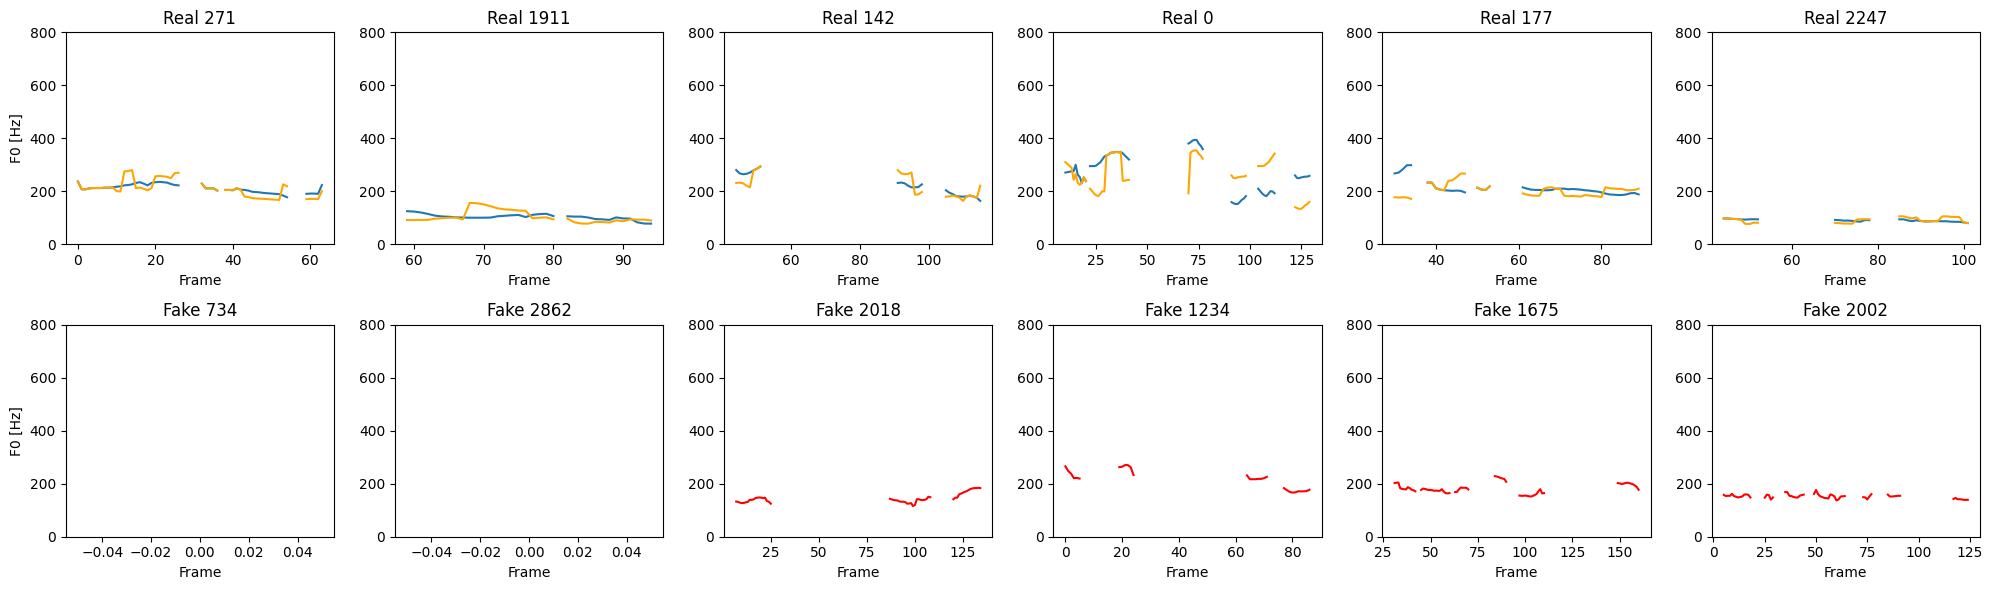

In [8]:
no_tracks = 6

idx_real = np.random.choice(len(df_real), no_tracks, replace=False)
idx_fake = np.random.choice(len(df_fake), no_tracks, replace=False)

fig, axes = plt.subplots(2, no_tracks, figsize=(20, 6), sharey=False)

# --- REAL + MOD ---
for i, idx in enumerate(idx_real):
    axes[0, i].plot(df_real["f0_traj"].iloc[idx])
    axes[0, i].plot(df_real["f0_traj_mod"].iloc[idx], color='orange')
    axes[0, i].set_title(f"Real {idx}")
    axes[0, i].set_ylim([0, 800])
    axes[0, i].set_xlabel("Frame")
    if i == 0:
        axes[0, i].set_ylabel("F0 [Hz]")

# --- FAKE ---
for i, idx in enumerate(idx_fake):
    axes[1, i].plot(df_fake["f0_traj"].iloc[idx], color='red')
    axes[1, i].set_title(f"Fake {idx}")
    axes[1, i].set_ylim([0, 800])
    axes[1, i].set_xlabel("Frame")
    if i == 0:
        axes[1, i].set_ylabel("F0 [Hz]")

plt.tight_layout()
plt.show()

### Compare using proxy scalar features distributions:
- Natural speech  
- Manipulated speech (our home-made modifications)  
- Speech from actual selected ASV19 generator

#### Procedure  
- Look for features where Cohen's d between natural speech and true deepfakes is high (> ~0.4/0.5)
- Tune manipulation parameters to match the distribution on those features  

In [9]:
# ---------- support functions ----------

def autocorr_decay(x, max_lag=50):
    x = x - np.mean(x)
    ac = np.correlate(x, x, mode="full")
    ac = ac[len(ac) // 2 :]
    ac /= ac[0] + 1e-8
    return np.mean(ac[1:max_lag])


def f0_concat_features(f0, hop_s):
    f0 = np.asarray(f0, dtype=float)

    voiced = ~np.isnan(f0)
    f0v = f0[voiced]

    if len(f0v) < 5:
        return None

    feats = {}

    # ================================
    # PITCH DISPERSION (global spread)
    
    feats["f0_std"]   = np.std(f0v)                     # ~ stat moment 2
    feats["f0_range"] = np.max(f0v) - np.min(f0v)       # peak-to-peak excursion
    feats["f0_iqr"]      = np.percentile(f0v, 75) - np.percentile(f0v, 25)  # robust spread
    feats["f0_p95_p5"]   = np.percentile(f0v, 95) - np.percentile(f0v, 5)   # robust excursion
    feats["f0_cv"]       = np.std(f0v) / np.mean(f0v)            # speaker-normalized dispersion

    # =================================
    # DISTRIBUTION SHAPE (stat moments 1, 3, 4)
    
    feats["f0_mean"]    = np.mean(f0v)     # central tendency
    feats["f0_skew"]     = skew(f0v)         # asymmetry
    feats["f0_kurtosis"] = kurtosis(f0v)     # tail heaviness

    # =================================
    # TEMPORAL DYNAMICS (delta F0)
    
    df0 = np.diff(f0v)
    
    feats["df0_std"]      = np.std(df0)           # slope variability
    feats["df0_mean_abs"] = np.mean(np.abs(df0))  # average movement magnitude
    feats["df0_max_abs"]  = np.max(np.abs(df0))   # strongest pitch jump

    # TAIL BEHAVIOR (rare jumps)
    feats["df0_p95"] = np.percentile(np.abs(df0), 95)
    thr = np.median(np.abs(df0)) * 3
    feats["df0_outlier_ratio"] = np.mean(np.abs(df0) > thr)

    # =================================
    # TEMPORAL STRUCTURE
    
    feats["f0_ac_decay"] = autocorr_decay(f0v)

    # ==========================================================
    # TEMPORAL CURVATURE 
    
    ddf0 = np.diff(df0)
    feats["ddf0_std"] = np.std(ddf0)     # curvature variability

    # ==========================================================
    # STRUCTURAL RATIOS  
    
    feats["dyn_ratio"]  = feats["df0_std"] / feats["f0_std"]      # dynamic energy relative to range
    feats["curv_ratio"] = feats["ddf0_std"] / feats["df0_std"]    # curvature relative to slope

    return feats

DYN_RATIO

======== FEATURE SUMMARY ========
Group            Mean      Std
------------------------------
Natural         0.471    0.204
Deepfake        0.600    0.182
Manipulated     0.670    0.178

Trend (low → high): Natural < Deepfake < Manipulated

Effect sizes (Cohen's d)
------------------------------
Natural vs Deepfake:   -0.664
Natural vs Manipulated: -1.041

Natural vs Deepfake strength:   medium
Natural vs Manipulated strength: large



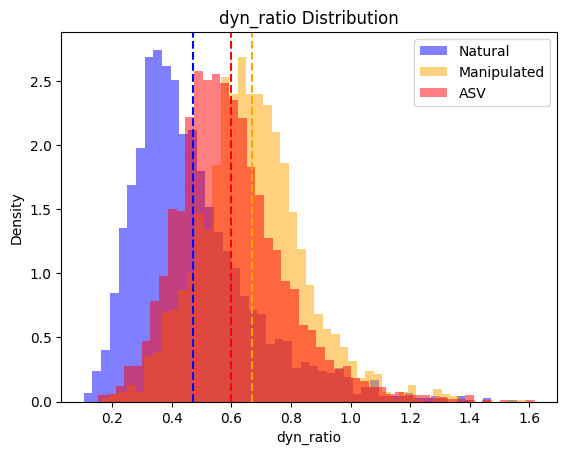

DF0_P95

======== FEATURE SUMMARY ========
Group            Mean      Std
------------------------------
Natural        16.173    9.482
Deepfake       21.281   11.637
Manipulated    40.420   23.744

Trend (low → high): Natural < Deepfake < Manipulated

Effect sizes (Cohen's d)
------------------------------
Natural vs Deepfake:   -0.481
Natural vs Manipulated: -1.341

Natural vs Deepfake strength:   medium
Natural vs Manipulated strength: large



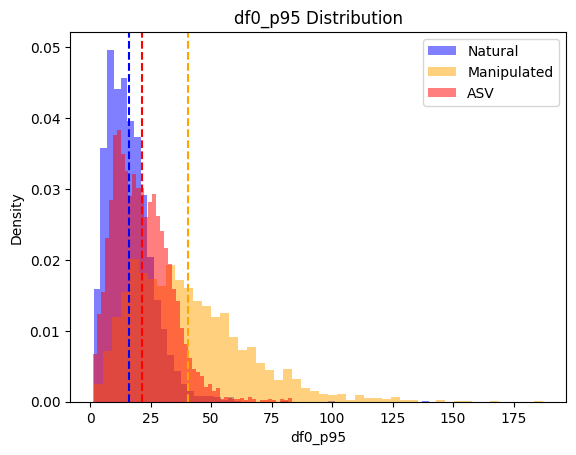

DF0_OUTLIER_RATIO

======== FEATURE SUMMARY ========
Group            Mean      Std
------------------------------
Natural         0.181    0.069
Deepfake        0.209    0.065
Manipulated     0.240    0.063

Trend (low → high): Natural < Deepfake < Manipulated

Effect sizes (Cohen's d)
------------------------------
Natural vs Deepfake:   -0.421
Natural vs Manipulated: -0.889

Natural vs Deepfake strength:   medium
Natural vs Manipulated strength: large



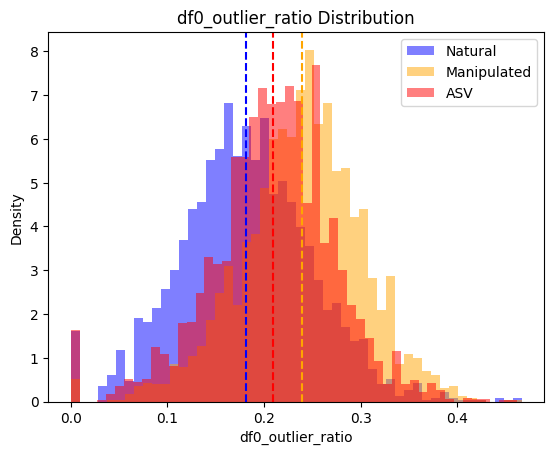

DDF0_STD

======== FEATURE SUMMARY ========
Group            Mean      Std
------------------------------
Natural        11.235    7.348
Deepfake       14.467    8.117
Manipulated    25.671   14.254

Trend (low → high): Natural < Deepfake < Manipulated

Effect sizes (Cohen's d)
------------------------------
Natural vs Deepfake:   -0.417
Natural vs Manipulated: -1.273

Natural vs Deepfake strength:   medium
Natural vs Manipulated strength: large



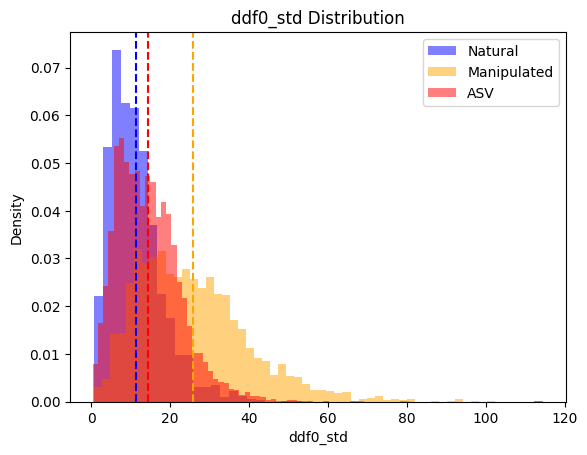

In [10]:
# All features
#proxy_features_list = ["f0_std", "f0_range", "f0_iqr", "f0_p95_p5", "f0_cv", "f0_mean", "f0_skew", "f0_kurtosis", "df0_std", "df0_mean_abs",  "df0_p95", "df0_outlier_ratio", "df0_max_abs", "f0_ac_decay", "ddf0_std", "dyn_ratio", "curv_ratio"]

# 'Best' for flatness (high Nat-ASV Cohen's d)
#proxy_features_list = ["df0_std", "df0_mean_abs", "df0_max_abs", "f0_ac_decay", "ddf0_std", "dyn_ratio"]
#proxy_features_list = ["df0_std", "ddf0_std", "dyn_ratio",]  # reduced set

# 'Best' for inconsistency (high Nat-ASV Cohen's d)
proxy_features_list = ["dyn_ratio", "df0_p95", "df0_outlier_ratio", "ddf0_std"]


feat_nat, feat_man, feat_fake, \
feat_nat_global, feat_man_global, feat_fake_global = compute_features_and_aggregate(
    df_real,
    df_fake,
    stft_params,
)

print_stats_and_plot(
    proxy_features_list,
    feat_nat,
    feat_man,
    feat_fake,
    feat_nat_global,
    feat_man_global,
    feat_fake_global,
)


### Shortcut to compute mean and std to train MLP

In [11]:
from sklearn.model_selection import train_test_split

def make_df_bonafide():
    base_path = '/Database/ASVspoof2019/public_released_data'

    def load_subset(file_path, dir_name, filter_col, path_col):
        df = pd.read_csv(file_path, sep=' ', header=None)
        return (
            df[df[filter_col] == 'bonafide']
              .assign(path=lambda df: df[path_col].apply(
                  lambda x: os.path.join(base_path, dir_name, f"{x}.flac")
              ))[['path']]
        )

    df_t = load_subset(os.path.join(base_path, "LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.train.trn.txt"),
                       "LA/ASVspoof2019_LA_train/flac", 4,1)
    df_d = load_subset(os.path.join(base_path, "LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.dev.trl.txt"),
                       "LA/ASVspoof2019_LA_dev/flac", 4,1)
    
    df = pd.concat([df_t, df_d], ignore_index=True)
    return df

def autocorr_decay(x, max_lag=50):
    x = x - np.mean(x)
    ac = np.correlate(x, x, mode='full')
    ac = ac[len(ac)//2:]
    ac /= ac[0] + 1e-8
    return np.mean(ac[1:max_lag])
        
def extract_proxy_scalars(feat):
    f0v = feat[feat != 0.0]

    if len(f0v) < 3:
        return np.zeros(10, dtype=np.float32)
    
    df0 = np.diff(f0v)
    ddf0 = np.diff(df0)

    f0_std = np.std(f0v)
    df0_std = np.std(df0)

    f0_ac_decay = autocorr_decay(f0v)
    df0_mean_abs = np.mean(np.abs(df0))
    df0_max_abs = np.max(np.abs(df0))
    df0_p95 = np.percentile(np.abs(df0), 95)
    thr = np.median(np.abs(df0)) * 3
    df0_outlier_ratio = np.mean(np.abs(df0) > thr)
    ddf0_std = np.std(ddf0)
    dyn_ratio = df0_std / f0_std
    curv_ratio = ddf0_std / df0_std

    return np.array([f0_std, f0_ac_decay, df0_std, df0_mean_abs, df0_max_abs,
                     df0_p95, df0_outlier_ratio, ddf0_std, dyn_ratio, curv_ratio])

In [13]:
import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader


class F0Dataset(torch.utils.data.Dataset):
    def __init__(self, df, stft_params, mod='flat', mean=None, std=None):
        self.df = df.reset_index(drop=True)
        self.stft_params = stft_params
        self.mod = mod
        self.mean = mean
        self.std = std

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        path = self.df.iloc[idx][0]

        filename = os.path.splitext(os.path.basename(path))[0]
        file = f'/home/smg/v-viola/moe_antideepfake/temp_feat/f0_asv19_no_pad/{filename}.npy'

        if not os.path.exists(file):
            x = load_audio(path, trim=True, normalize=True)
            x = torch.tensor(x)
            feat = extract_f0(
                x,
                fs=self.stft_params.sample_rate,
                win_size=self.stft_params.win_size,
                hop_size=self.stft_params.hop_size
            )
            feat = np.nan_to_num(feat, nan=0.0)
            np.save(file, feat)
        else:
            feat = np.load(file)

        label = 0

        if np.all(feat == 0.0):
            label = np.random.randint(0, 2)
            feat = np.zeros(10)

        if idx % 2 == 0:
            feat = apply_f0_mod(
                feat,
                mod=self.mod,
                hop_s=self.stft_params.hop_sec,
            )
            label = 1

        feat = extract_proxy_scalars(feat)

        feat = torch.tensor(feat, dtype=torch.float32)

        # normalization happens here
        if self.mean is not None:
            feat = (feat - self.mean) / (self.std + 1e-8)

        return feat, label


In [12]:
df_all = make_df_bonafide()
df_train, _ = train_test_split(
    df_all,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

df_train = pd.DataFrame(df_train.values.repeat(2, axis=0), columns=df_train.columns)
print(len(df_train))

8204


In [14]:
train_dataset = F0Dataset(df_train, stft_params, mod=mod)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=False)

In [15]:
feature_sum = torch.zeros(10)
feature_sq_sum = torch.zeros(10)
count = 0

#for feats, _ in train_loader:
for feats, _ in tqdm(train_loader):

    feature_sum += feats.sum(dim=0)
    feature_sq_sum += (feats ** 2).sum(dim=0)
    count += feats.size(0)

mean = feature_sum / count
std = torch.sqrt(feature_sq_sum / count - mean**2)

print("Mean:", mean)
print("Std:", std)


100%|████████████████████████████████████████████████████████████████████| 129/129 [00:10<00:00, 12.83it/s]

Mean: tensor([2.2393e+01, 3.4486e-03, 1.2742e+01, 6.7704e+00, 5.3644e+01, 2.8033e+01,
        2.0125e-01, 1.8249e+01, 5.5215e-01, 1.3292e+00])
Std: tensor([13.8908,  0.0507,  9.3971,  4.5291, 42.6525, 22.3822,  0.0860, 13.9947,
         0.2508,  0.3560])


## Inspect ASV19 TTS

In [ ]:
def prepare_audio_window(x, max_len=48000, is_eval=True):
    x_len = x.shape[0]

    # --- repeat signal if too short ---
    while x_len < max_len:
        num_samples = min(x_len, max_len - x_len)
        x = torch.cat([x, x[:num_samples]], dim=0)
        x_len = x.shape[0]

    if not is_eval:
        # --- random crop (training mode) ---
        last_valid_start_sample = x_len - max_len

        if last_valid_start_sample != 0:
            start_sample = random.randrange(0, last_valid_start_sample)
        else:
            start_sample = 0

        x_pad = x[start_sample : start_sample + max_len]

    else:
        # --- deterministic middle crop (evaluation mode) ---
        num_windows = round(x_len / max_len)

        if num_windows % 2 == 1:  # odd number of windows
            middle = num_windows // 2
        else:  # even number of windows
            middle = (num_windows // 2) - 1

        start_sample = middle * max_len
        x_pad = x[start_sample : start_sample + max_len]

    return x_pad


In [ ]:
p = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.train.trn.txt"
f = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_train/flac"

# p = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.dev.trl.txt"
# f = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_dev/flac"

# p = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.eval.trl.txt"
# f = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_eval/flac"

df_all = pd.read_csv(p, sep=" ", header=None)

In [ ]:
df_target = (
    df_all[df_all[3] == f'{algorithm}']
    .assign(path=lambda df_all: df_all[1].apply(
        lambda x: os.path.join(f, f"{x}.flac")
    ))[['path']]
)

target_list = df_target['path'].tolist()
print(len(target_list))

In [ ]:
# ----- pick 5 random examples -----
sample_paths = random.sample(target_list, 5)


mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=16000,
    n_fft=1024,
    hop_length=256,
    n_mels=128
)

spec_transform = torchaudio.transforms.Spectrogram(
    n_fft=1024,
    hop_length=256,
    power=2
)

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(20, 6))

for col, path in enumerate(sample_paths):

    y = load_audio(path, trim=True, normalize=True)
    y = torch.tensor(y)

    y = prepare_audio_window(y, is_eval=True)

    # add batch/channel dimension
    y = y.unsqueeze(0)

    # --- compute mel spectrogram ---
    mel_spec = mel_transform(y)
    mel_spec_db = torchaudio.functional.amplitude_to_DB(
        mel_spec,
        multiplier=10.0,
        amin=1e-10,
        db_multiplier=0
    )

    # --- compute linear spectrogram ---
    spec = spec_transform(y)
    spec_db = torchaudio.functional.amplitude_to_DB(
        spec,
        multiplier=10.0,
        amin=1e-10,
        db_multiplier=0
    )

    # remove batch dimension
    mel_img = mel_spec_db.squeeze().numpy()
    spec_img = spec_db.squeeze().numpy()

    # --- plot mel ---
    axes[0, col].imshow(mel_img, origin="lower", aspect="auto")
    axes[0, col].set_title(f"Track {col+1}")
    axes[0, col].set_xlabel("Time")
    axes[0, col].set_ylabel("Mel Freq")

    # --- plot linear ---
    axes[1, col].imshow(spec_img, origin="lower", aspect="auto")
    axes[1, col].set_xlabel("Time")
    axes[1, col].set_ylabel("Linear Freq")

plt.tight_layout()
plt.show()
